# Are songs getting shorter?

The working behind the [findings report](../findings/README.md), using a sample of tracks collected from Spotify in late 2025 and published on Kaggle.

The calculations live in [`findings/analysis.py`](../findings/analysis.py) and the charts in [`findings/charts.py`](../findings/charts.py), so this notebook, the report and the tests all use the same code.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "findings").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "findings"))

import analysis as an
import charts

## 0. The data

[`data/prepare.py`](../data/prepare.py) has already tidied the download. Each row is one copy of a track. Copies of the same song share a `song` key, and the most popular copy of each song is marked `counted`.

In [2]:
tracks = an.tracks()
tracks.head()

,track_id,song,counted,track,artist,album,release_type,release_date,year,popularity,artist_popularity,artist_followers,explicit,minutes,track_number,album_tracks
0,61GEP8lryEfcuEgBMbRmNi,alone and forsaken | hank williams,True,Alone And Forsaken,Hank Williams,Moanin' The Blues (Expanded Edition),album,1952-09-12,1952,45,55,1067339,False,2.02,11,12
1,760clbeDBWmBsBLbszWuNZ,i'm a man | bo diddley,True,I'm A Man,Bo Diddley,Bo Diddley,album,1958-01-01,1958,55,44,333376,False,2.74,2,12
2,0Vy7wsXNFrbNc6UTWoScnM,over the rainbow | the mystics,True,Over the Rainbow,The Mystics,Presenting The Mystics,compilation,1959-02-11,1959,8,27,18184,False,2.28,5,9
3,0AQquaENerGps8BQmbPw14,big iron | marty robbins,True,Big Iron,Marty Robbins,Gunfighter Ballads And Trail Songs,album,1959-06-30,1959,71,60,626733,False,3.92,1,15
4,4f8hBeMXMvssn6HtFAtblo,el paso | marty robbins,True,El Paso,Marty Robbins,Gunfighter Ballads And Trail Songs,album,1959-06-30,1959,64,61,626733,False,4.32,10,15


In [3]:
pd.Series(an.data_notes())

raw_rows                  8582
rows                      8581
songs                     7919
artists                   2546
first_year                1952
last_year                 2025
latest              2025-10-31
repeats                    662
no_genre              0.391634
new_year                   667
no_artist                    3
not_music                    1
exact_duplicates             0
since_2000             0.92095
dtype: object

Many songs appear more than once. Here is one, with very different scores on its two releases.

In [4]:
an.example()

,track,artist,album,release_type,popularity
5491,Mood (feat. iann dior),24kGoldn,Mood (feat. iann dior),single,6
5845,Mood (feat. iann dior),24kGoldn,El Dorado,album,77


## 1. Songs are getting shorter

The typical (median) length of songs released each year, counting each song once.

In [5]:
an.length_by_period()

,songs,typical,short
2000 to 2009,856,3.735,0.185748
2010 to 2014,1286,3.790,0.143079
2015 to 2019,2068,3.460,0.252901
2020 to 2025,3083,3.040,0.471943


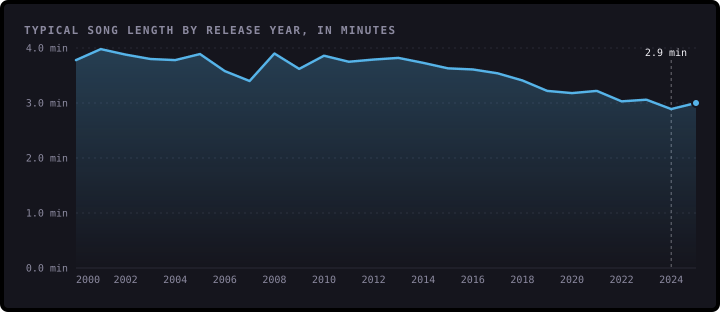

In [6]:
charts.song_length()

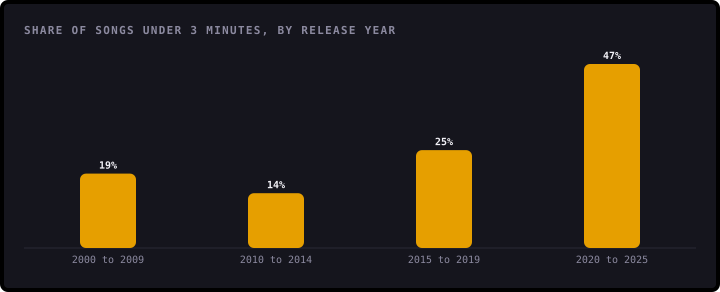

In [7]:
charts.short_songs()

The same fall shows up for album tracks only and for popular songs only, so it isn't just more short singles or more obscure songs being collected.

In [8]:
an.length_checks()

,2000 to 2009,2020 to 2025
Every song,3.735,3.04
Album tracks only,3.790,3.22
Popular songs only (50 or more),3.840,3.15


## 2. The same song can get very different scores

In [9]:
an.copies().describe()

,copies,best,worst,gap
count,580.000000,580.000000,580.000000,580.000000
mean,2.141379,73.168966,42.596552,30.572414
std,0.412262,11.823357,28.033153,28.748626
min,2.000000,0.000000,0.000000,0.000000
25%,2.000000,69.000000,6.000000,6.000000
50%,2.000000,75.000000,53.000000,20.000000
75%,2.000000,81.000000,66.000000,60.500000
max,5.000000,92.000000,91.000000,88.000000


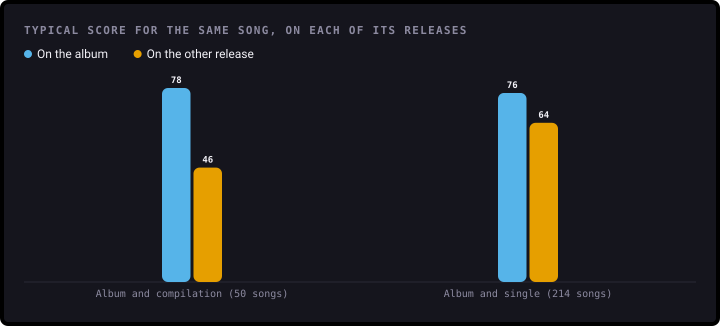

In [10]:
charts.same_song()

In [11]:
an.by_release_type()

release_type
album          62.0
single         51.0
compilation    43.0
Name: popularity, dtype: float64

## 3. A score of zero doesn't mean nobody listens

In [12]:
zeros = an.zeros()
zeros["examples"]

,track,artist,artist_popularity
2491,Blank Space - Voice Memo,Taylor Swift,100
2492,I Wish You Would - Voice Memo,Taylor Swift,100
5613,Smokin Out The Window,Bruno Mars,90


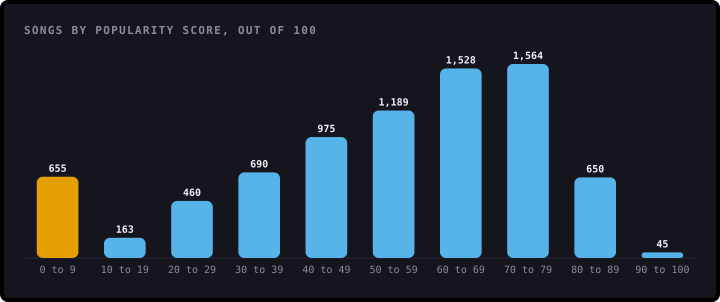

In [13]:
charts.scores()

## 4. Big artists help, but they don't decide

In [14]:
an.by_artist()

,songs,typical,low,high
Under 50,1303.0,33.0,20.0,43.0
50s,827.0,47.0,33.0,58.0
60s,1307.0,58.0,43.0,69.0
70s,1625.0,66.0,51.0,75.0
80s,2099.0,65.0,54.0,76.0
90 and up,758.0,70.0,61.0,76.0


In [15]:
an.artist_link()

{'r': np.float64(0.5247472473005254),
 'explained': np.float64(0.2753596735494787),
 'top_under_50': np.float64(0.09762532981530343)}

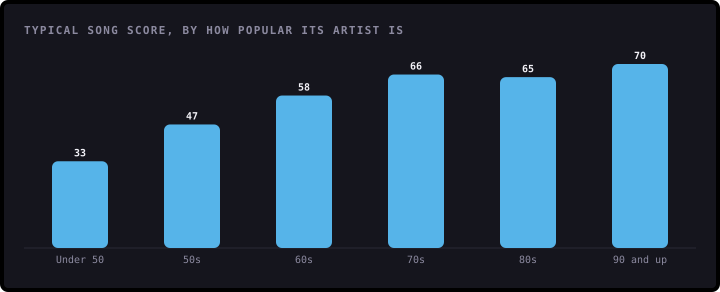

In [16]:
charts.by_artist()

## 5. Length barely matters, except for very short tracks

In [17]:
an.by_length()

,songs,typical
Under 2,433.0,41.0
2 to 2.5,715.0,47.0
2.5 to 3,1294.0,55.0
3 to 3.5,1805.0,61.0
3.5 to 4,1719.0,63.0
4 to 5,1447.0,61.0
5 and over,506.0,56.5


In [18]:
an.length_link()

{'r': np.float64(0.12155096173698812),
 'r_two_plus': np.float64(0.05757336208117493)}

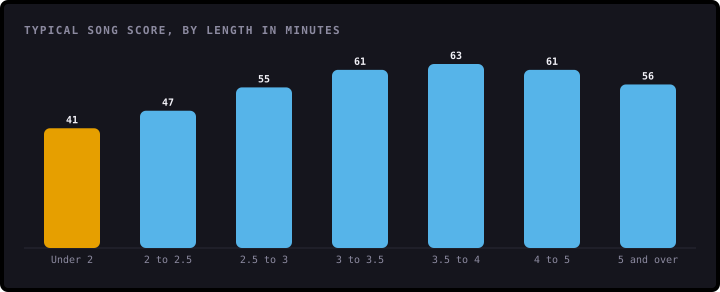

In [19]:
charts.by_length()

## 6. More songs are explicit, and explicit songs score higher

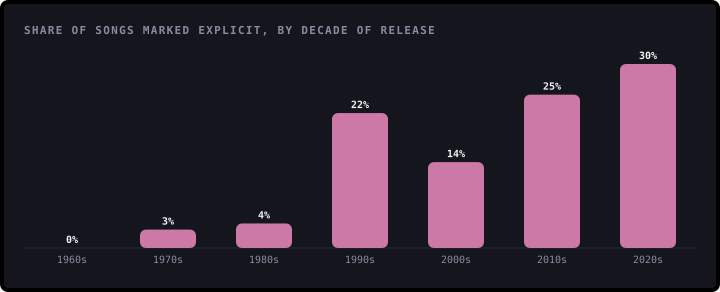

In [20]:
charts.explicit()

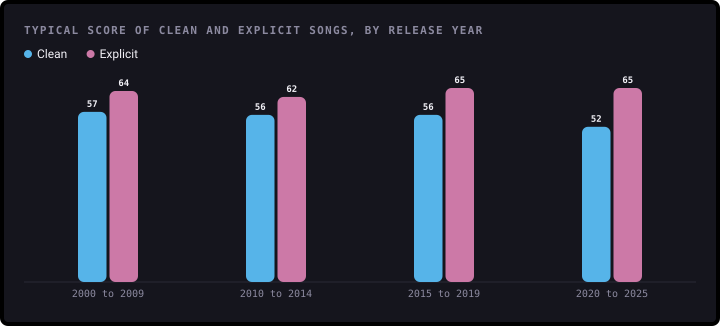

In [21]:
charts.explicit_scores()

A check using genres, which only 61% of tracks have: explicit tracks score higher both inside and outside hip-hop and rap.

In [22]:
an.explicit_by_genre()

explicit,clean,explicit,explicit_share
artist_genres,,,
Everything else,55.0,65.0,0.130784
Hip-hop and rap,58.0,65.0,0.699552


## 7. What the first version got wrong

The first version ranked artists by how many rows they had in the file, and charted rows per year. Both measure the sample, not popularity or the music industry.

In [23]:
old = an.first_version()
old["top"]

artist
Taylor Swift         324
The Weeknd           141
Lana Del Rey          99
Ariana Grande         94
Nirvana               91
Drake                 84
Post Malone           83
The Neighbourhood     77
Lady Gaga             70
Olivia Rodrigo        68
Name: count, dtype: int64

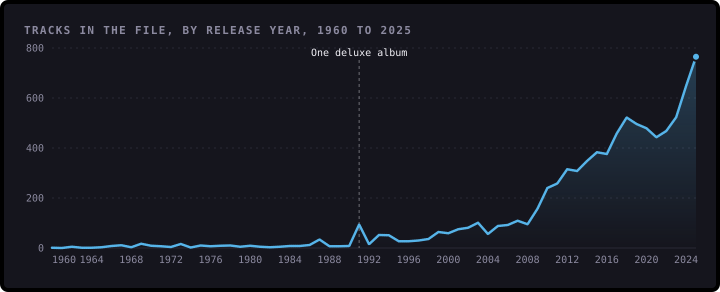

In [24]:
charts.rows_by_year()